# Task 19: Manual Chi-Square Test

## Objective
To perform a chi-square test of independence between categorical
features and the target column by manually calculating observed
frequencies, expected frequencies, and the chi-square statistic
without using statistical testing libraries.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print("\nColumns:", list(df.columns))

Dataset Shape: (1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [2]:
target_column = "target"

if target_column not in df.columns:
    raise ValueError("The dataset must contain a 'target' column.")

candidate_columns = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

categorical_columns = [
    col for col in candidate_columns if col in df.columns
]

print("Categorical columns selected:", categorical_columns)

Categorical columns selected: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


## Observed and Expected Frequencies

Observed frequency is the actual count for each combination of a
categorical feature and target class.

Expected frequency is calculated using:

Expected Frequency = (Row Total × Column Total) / Grand Total

In [3]:
def manual_chi_square(feature, target):
    data = pd.DataFrame({
        "feature": feature,
        "target": target
    }).dropna()

    feature_values = list(pd.unique(data["feature"]))
    target_values = list(pd.unique(data["target"]))

    # Calculate observed frequencies manually
    observed = []

    for feature_value in feature_values:
        row = []

        for target_value in target_values:
            count = 0

            for i in range(len(data)):
                if (
                    data["feature"].iloc[i] == feature_value
                    and data["target"].iloc[i] == target_value
                ):
                    count += 1

            row.append(count)

        observed.append(row)

    # Calculate row totals, column totals and grand total
    row_totals = [sum(row) for row in observed]

    column_totals = []

    for j in range(len(target_values)):
        column_total = 0

        for i in range(len(feature_values)):
            column_total += observed[i][j]

        column_totals.append(column_total)

    grand_total = sum(row_totals)

    # Calculate expected frequencies and chi-square statistic
    expected = []
    chi_square = 0

    for i in range(len(feature_values)):
        expected_row = []

        for j in range(len(target_values)):
            if grand_total == 0:
                expected_frequency = 0
            else:
                expected_frequency = (
                    row_totals[i] * column_totals[j] / grand_total
                )

            expected_row.append(expected_frequency)

            if expected_frequency > 0:
                chi_square += (
                    (observed[i][j] - expected_frequency) ** 2
                    / expected_frequency
                )

        expected.append(expected_row)

    degrees_of_freedom = (
        (len(feature_values) - 1) * (len(target_values) - 1)
    )

    return {
        "feature_values": feature_values,
        "target_values": target_values,
        "observed": observed,
        "expected": expected,
        "chi_square": chi_square,
        "degrees_of_freedom": degrees_of_freedom,
        "grand_total": grand_total
    }

In [4]:
results = {}

for col in categorical_columns:
    result = manual_chi_square(df[col], df[target_column])
    results[col] = result

    print("\n" + "=" * 50)
    print("Feature:", col)
    print("Observed Frequencies:")

    observed_df = pd.DataFrame(
        result["observed"],
        index=result["feature_values"],
        columns=result["target_values"]
    )
    print(observed_df)

    print("\nExpected Frequencies:")

    expected_df = pd.DataFrame(
        result["expected"],
        index=result["feature_values"],
        columns=result["target_values"]
    )
    print(expected_df.round(3))

    print("\nChi-Square Statistic:", round(result["chi_square"], 4))
    print("Degrees of Freedom:", result["degrees_of_freedom"])


Feature: sex
Observed Frequencies:
     0    1
1  413  300
0   86  226

Expected Frequencies:
         0        1
1  347.109  365.891
0  151.891  160.109

Chi-Square Statistic: 80.0737
Degrees of Freedom: 1

Feature: cp
Observed Frequencies:
     0    1
0  375  122
1   33  134
2   65  219
3   26   51

Expected Frequencies:
         0        1
0  241.954  255.046
1   81.300   85.700
2  138.260  145.740
3   37.486   39.514

Chi-Square Statistic: 280.9822
Degrees of Freedom: 3

Feature: fbs
Observed Frequencies:
     0    1
0  417  455
1   82   71

Expected Frequencies:
         0        1
0  424.515  447.485
1   74.485   78.515

Chi-Square Statistic: 1.7368
Degrees of Freedom: 1

Feature: restecg
Observed Frequencies:
     0    1
1  204  309
0  283  214
2   12    3

Expected Frequencies:
         0        1
1  249.743  263.257
0  241.954  255.046
2    7.302    7.698

Chi-Square Statistic: 35.7843
Degrees of Freedom: 2

Feature: exang
Observed Frequencies:
     0    1
0  225  455
1  274 

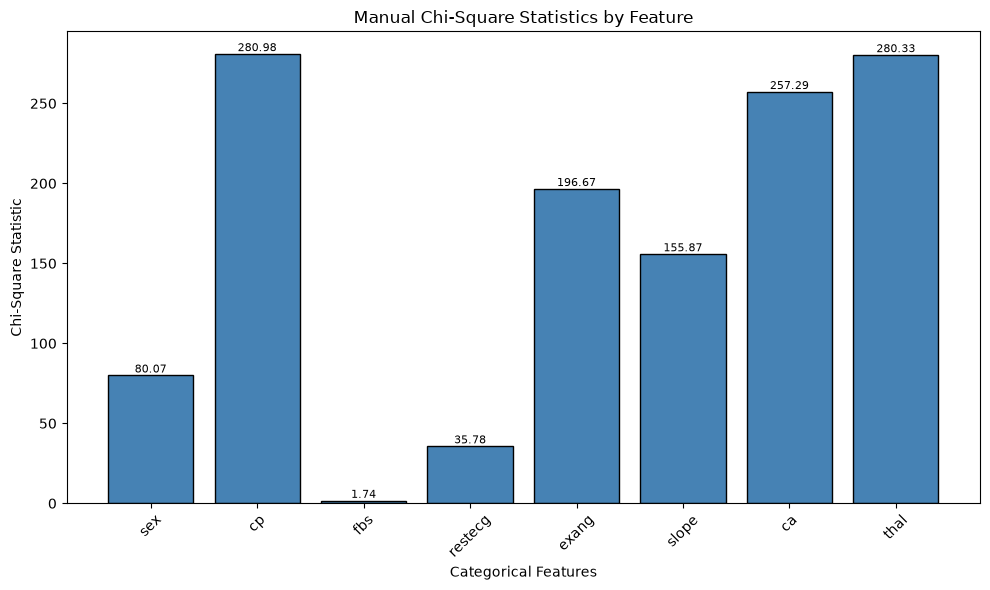

In [5]:
feature_names = []
chi_square_values = []

for col, result in results.items():
    feature_names.append(col)
    chi_square_values.append(result["chi_square"])

plt.figure(figsize=(10, 6))

bars = plt.bar(
    feature_names,
    chi_square_values,
    color="steelblue",
    edgecolor="black"
)

plt.xlabel("Categorical Features")
plt.ylabel("Chi-Square Statistic")
plt.title("Manual Chi-Square Statistics by Feature")
plt.xticks(rotation=45)

for bar, value in zip(bars, chi_square_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

## Conclusion

In this task, chi-square statistics were calculated manually for
categorical features against the target column. Observed and expected
frequencies were computed using loops and mathematical formulas.
The resulting statistics help compare categorical feature relationships
with the target.

A large chi-square statistic indicates a greater difference between
observed and expected frequencies, but statistical significance should
be determined using the appropriate degrees of freedom and significance
level. Expected cell counts should also be checked before interpreting
the results.